# 04 · Perfil de normalidade e limites por atributo (v2)
**CRISP-DM:** Modelagem

**Perfil contextual (proposto):** mediana e escala robusta (1,4826 × MAD) de cada indicador por recurso × tipo de dia (útil/não útil) × hora, em **janelas de 1 h** de agosto. Para um período qualquer:

z = (valor − mediana do contexto) / escala do contexto, contado só no sentido desfavorável (volume nos dois sentidos; 4xx, 5xx e latência só na alta).

**Limite por atributo:** para cada tamanho de faixa L (15, 30 e 60 min), os z de agosto são calculados **fora da amostra** (validação cruzada, 4 dobras semanais). O limite do indicador a no recurso r é c × percentil 99 desses z (mínimo 3), com c ≥ 1 escolhido para no máximo 5% de períodos residuais em agosto. Com essa meta, c = 1: **o limite de cada indicador é o seu próprio percentil 99**.

> **Ponto de operação (decisão do autor após a primeira avaliação):** a primeira execução usou meta de 1% (c ≈ 1,7), com sensibilidade de 28% e especificidade de 99,3%. Como a consulta só ocorre quando já existe um incidente aberto, aceita-se um pouco mais de 'falso residual' em troca de sensibilidade. O notebook 06 relata os pontos 1%, 2% e 5%.

**Decisão:** o período é **Residual** se algum indicador passa do seu limite; o **indicador responsável** é o que mais passou (em múltiplos do limite).

As faixas de 15 e 30 min usam o **mesmo perfil de 1 h** (volume convertido à escala horária); só os limites são recalibrados, porque períodos curtos têm mais variação.

In [1]:
%run ./00_funcoes.ipynb

00_funcoes (v2) carregado · /home/wsl/gh/mestrado/claude9/v2


In [2]:
import pickle
jan1h = pd.read_parquet(RESULTADOS / "02_janelas_60min.parquet")
periodos = {60: jan1h}
for L in (15, 30):
    periodos[L] = pd.read_parquet(RESULTADOS / f"02_janelas_{L}min.parquet")
for L in periodos:
    periodos[L] = com_semana_anterior(periodos[L], periodos[L])

In [3]:
calib = {}
for nome, fab in METODOS.items():
    for L in FAIXAS_L:
        calib[(nome, L)] = calibrar(jan1h, periodos[L], fab)
        print(f"{nome:30s} L={L:>2} min · c = {calib[(nome, L)]['c']:.2f}")

Perfil contextual (proposto)   L=15 min · c = 1.00


Perfil contextual (proposto)   L=30 min · c = 1.00


Perfil contextual (proposto)   L=60 min · c = 1.00
z-score global                 L=15 min · c = 1.00


z-score global                 L=30 min · c = 1.00
z-score global                 L=60 min · c = 1.00


Semana anterior                L=15 min · c = 1.00


Semana anterior                L=30 min · c = 1.00
Semana anterior                L=60 min · c = 1.00


## Limites do método proposto (múltiplos de z)

In [4]:
lim = {L: calib[(PROPOSTO, L)]["limite"].rename(index=rot).rename(columns=INDICADOR).sort_index() for L in FAIXAS_L}
display(pd.concat(lim, axis=1).round(1))

15                                      30                                      60                                 
    volume erros 4xx erros 5xx latência p95 volume erros 4xx erros 5xx latência p95 volume erros 4xx erros 5xx latência p95
E01   14.2       9.2       3.0          9.8   12.6       7.8       3.0          8.9    9.9       7.1       3.0          8.6
E02   10.3       4.2       3.8         17.7   10.1       3.9       3.5         16.6   10.2       3.6       3.0         15.4
E03   10.7       5.5       3.0         23.6    6.7       4.0       3.0         22.0    5.0       3.8       3.0         21.6
E04   20.5      85.3       3.0         11.9   13.5      84.9       3.0         12.5    7.2      85.9       3.0         12.5
E05   33.6       8.0       3.0         14.2   25.3       6.9       3.0         10.8    9.6       4.4       3.0          7.7
E06   16.9       3.5       3.0          7.5   12.4       3.0       3.0          8.0   12.3       3.0       3.0          9.7
E07   14.4      49.3       3.0         13.4   11.7      47.9       3.2         13.7    8.7      46.2       4.1         11.8
E08    7.8      20.0       3.0         11.0    7.4      19.8       3.0         10.4    7.2      18.8       3.0         10.6
E09   12.8       8.8       3.0         10.7   11.0       7.1       3.0          9.1    9.5       4.5       3.0          9.4
E10   14.2       3.0      21.7          7.3   14.2       3.0      21.9          6.0   14.2       3.0      22.2          4.4
E11   23.4       3.3       3.0          5.5   20.9       3.0       3.0          5.3   22.2       3.0       3.0          5.3
E12   10.7       7.3      20.8         11.5   10.0       6.1      17.9         10.3    7.2       5.1      16.9          9.7

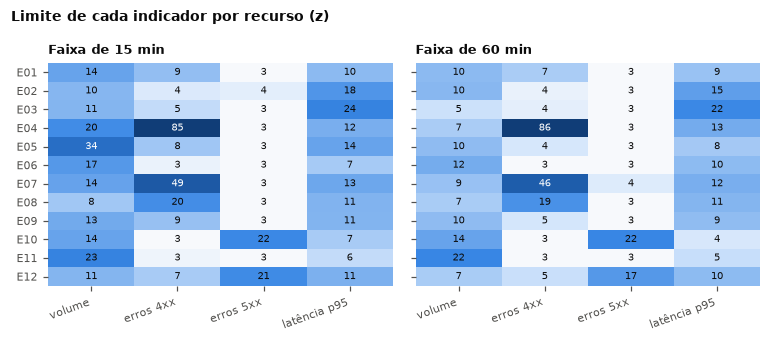

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.1), sharey=True)
for ax, L in zip(axes, (15, 60)):
    v = lim[L]
    ax.imshow(np.log10(v.to_numpy()), cmap=CMAP_SEQ, vmin=np.log10(3), vmax=2, aspect="auto")
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            ax.text(j, i, f"{v.iat[i, j]:.0f}", ha="center", va="center", fontsize=6.3,
                    color="white" if np.log10(v.iat[i, j]) > 1.45 else TXT1)
    ax.set_xticks(range(v.shape[1]))
    ax.set_xticklabels(v.columns, rotation=20, ha="right")
    ax.set_yticks(range(v.shape[0]))
    ax.set_yticklabels(v.index)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(f"Faixa de {L} min", loc="left")
fig.suptitle("Limite de cada indicador por recurso (z)", x=0.01, ha="left", fontsize=9, fontweight="bold")
fig.tight_layout()
salvar(fig, "fig_limites")
plt.show()

Limites maiores em 15 min refletem a maior variação dos períodos curtos. Limites muito altos (por exemplo, 4xx em alguns recursos) indicam picos reais frequentes em agosto: nesses recursos, só desvios grandes daquele indicador serão marcados como Residual.

## Alarmes em agosto (fora da amostra), por recurso

In [6]:
alarmes = {}
for (nome, L), cal in calib.items():
    alarmes[(nome, L)] = (cal["razao_cal"] > cal["c"]).groupby(cal["rec_cal"].to_numpy()).mean()
alarmes = pd.DataFrame(alarmes).rename(index=rot).sort_index()
display(alarmes.round(3))
print("média:", alarmes.mean().round(4).to_dict())

Perfil contextual (proposto)               z-score global               Semana anterior              
                              15     30     60             15     30     60              15     30     60
E01                        0.033  0.034  0.034          0.034  0.033  0.035           0.035  0.034  0.035
E02                        0.038  0.038  0.032          0.029  0.030  0.032           0.027  0.035  0.041
E03                        0.033  0.028  0.028          0.021  0.020  0.020           0.033  0.031  0.031
E04                        0.034  0.034  0.034          0.034  0.032  0.024           0.035  0.033  0.031
E05                        0.033  0.029  0.026          0.025  0.023  0.020           0.026  0.024  0.024
E06                        0.037  0.038  0.026          0.030  0.028  0.024           0.035  0.035  0.036
E07                        0.037  0.035  0.038          0.035  0.035  0.032           0.037  0.037  0.036
E08                        0.032  0.032  0.035          0.032  0.032  0.035           0.032  0.033  0.035
E09                        0.033  0.032  0.034          0.031  0.035  0.035           0.036  0.036  0.035
E10                        0.033  0.032  0.032          0.029  0.030  0.031           0.039  0.040  0.038
E11                        0.034  0.032  0.032          0.018  0.018  0.017           0.029  0.036  0.036
E12                        0.039  0.040  0.042          0.039  0.032  0.032           0.040  0.041  0.041

média: {('Perfil contextual (proposto)', 15): 0.0346, ('Perfil contextual (proposto)', 30): 0.0337, ('Perfil contextual (proposto)', 60): 0.0326, ('z-score global', 15): 0.0297, ('z-score global', 30): 0.0288, ('z-score global', 60): 0.0282, ('Semana anterior', 15): 0.0337, ('Semana anterior', 30): 0.0347, ('Semana anterior', 60): 0.035}


## Residual real em agosto (faixa de 60 min, método proposto): qual indicador?
Períodos de agosto marcados como residuais fora da amostra: dá uma ideia de que tipo de desvio real acontece nesses recursos.

In [7]:
cal = calib[(PROPOSTO, 60)]
p = recortar(periodos[60], TREINO)
dobra_p, dobra_1h = dobras_semanais(p), dobras_semanais(recortar(jan1h, TREINO))
tr1h = recortar(jan1h, TREINO)
vezes = pd.DataFrame(index=p.index, columns=ATRIBUTOS, dtype=float)
for k in range(4):
    m = Perfil().ajustar(tr1h[dobra_1h != k])
    vezes.loc[dobra_p == k] = (z_direcional(m.z(p[dobra_p == k])) / cal["limite"].reindex(p.loc[dobra_p == k, "recurso"]).to_numpy()).to_numpy()
res = (vezes > 1).any(axis=1)
ind = vezes[res].astype(float).idxmax(axis=1).map(INDICADOR)
print(f"{int(res.sum())} períodos residuais de 1 h em agosto ({res.mean():.1%})")
ind.value_counts()

291 períodos residuais de 1 h em agosto (3.3%)


volume          90
latência p95    82
erros 4xx       75
erros 5xx       44
Name: count, dtype: int64

In [8]:
with open(RESULTADOS / "04_calibracao.pkl", "wb") as f:
    pickle.dump(calib, f)
pd.concat(lim, axis=1).to_csv(RESULTADOS / "04_limites.csv")
alarmes.to_csv(RESULTADOS / "04_alarmes_agosto.csv")
salvar_json({f"{n} | {L}": round(c["c"], 3) for (n, L), c in calib.items()}, "04_multiplicadores.json")
salvar_json(dict(residuais_agosto_60=int(res.sum()), frac=float(res.mean()),
                 indicadores=ind.value_counts().to_dict()), "04_resumo.json")